# MARS Airbrake — Maximum Petal Area

This notebook derives the airbrake petal area as a function of the petal angle $\theta_p$ and finds the largest petal area that still fits around the launch rail and fins.

**Method**
1. **Angular budget:** fins, rail and clearances set the largest allowed petal angle $\theta_{p,\max}$ (Figure 1).
2. **Petal geometry:** derive $A_{petal}(\theta_p)$ from the three-petal cross-section (Figure 2).
3. **Check against last year:** reproduce the 2025–26 MATLAB/report values.
4. **Constrained maximum:** evaluate $A_{petal}$ over $0 < \theta_p \le \theta_{p,\max}$ and take the largest value.

All lengths are in inches; angles are in radians unless marked otherwise.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Circle, Rectangle
from scipy.optimize import brentq

In [2]:
# PIPELINE is True when this notebook is run from 25_26_MoS_Parameters / Test_Flight_MoS.
#   True  -> skip the printouts and plots
#   False -> opened on its own, show everything
PIPELINE = globals().get("PIPELINE", False)
SHOW_INFO = not PIPELINE   # only print / draw plots when run on its own

## Inputs

In [3]:
D         = 6.18      # [in] body diameter (rail, fins and petal chord all sit on this circle)
w_rail    = 1.50      # [in] rail guide / rail button width
t_fin     = 0.37523   # [in] fin root thickness
s_tol     = 0.10      # [in] arc-length clearance on EACH side of the rail
c_tol     = 0.5712073340690926+0.25      # [in] actuation tolerance / non-exposed petal length (c)
theta_total = np.pi/3 # [rad] mid-pedal to mid-fin

R_val = D / 2

## 1. Angular budget → $\theta_{p,\max}$

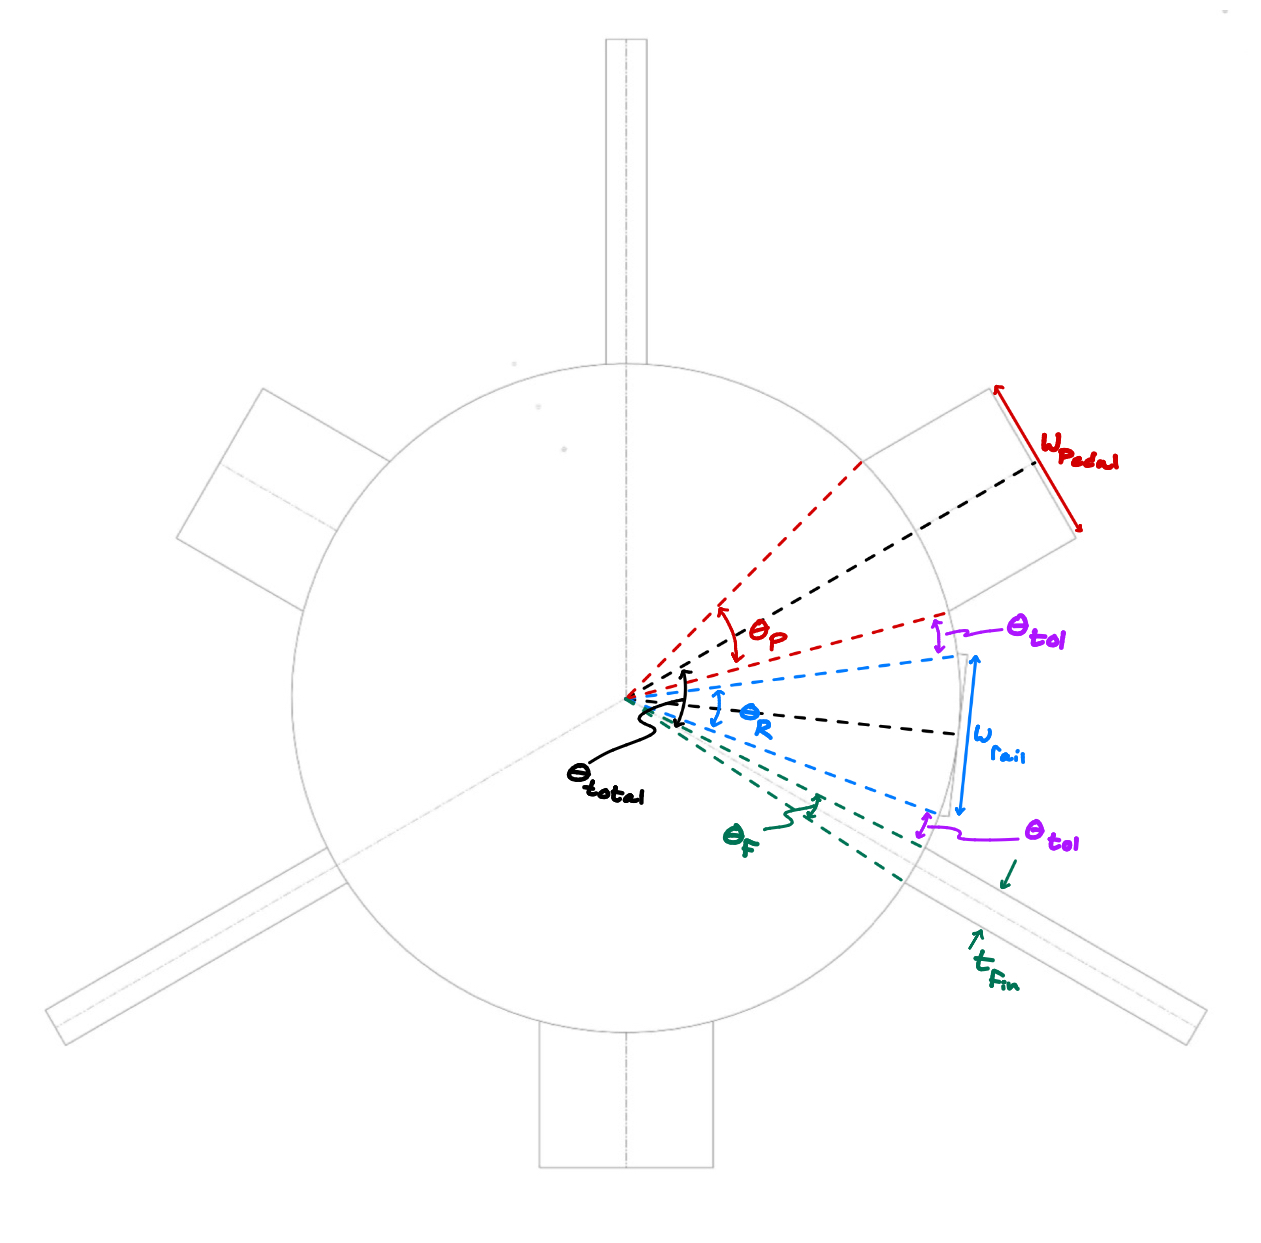

*Figure 1 — Angular layout of petals, rail and fins.*

Petals and fins alternate every $120^o$, so the wedge from a petal centerline to the next fin centerline is $60^o$. The rail sits in one of these wedges, which is therefore the most crowded one and sets the limit. Walking around that wedge from the petal centerline to the fin centerline:

$$\frac{\theta_p}{2} + 2\theta_{tol} + \theta_R + \frac{\theta_F}{2} = \theta_{total}$$

with
- $\theta_{tol} = s_{tol}/R$ — arc-length clearance converted to angle,
- $\theta_R = 2\arctan\!\left(\dfrac{w_{rail}}{2R}\right)$ — the angle subtended by a flat rail of width $w_{rail}$ sitting tangent to the body,
- $\theta_F = t_{fin}/R$ — the full fin-root thickness as an angle; only half of it falls in this wedge.

In [4]:
#Find the theta values

theta_tol = s_tol/R_val
theta_R = 2 * np.arctan(w_rail/D)
theta_F = t_fin/R_val

print(np.rad2deg(theta_tol))
print(np.rad2deg(theta_R))
print(np.rad2deg(theta_F))

1.8542323467016935
27.28582955198014
6.957636034528764


In [5]:
theta_p = theta_p = 2*(theta_total - (2 * theta_tol) - (0.5 * theta_F) - (theta_R))

print("The maximum pedal angle is " + str(np.rad2deg(theta_p)) + " " + "degrees")

The maximum pedal angle is 51.053775474704175 degrees


## 2. Petal geometry → $A_{petal}$

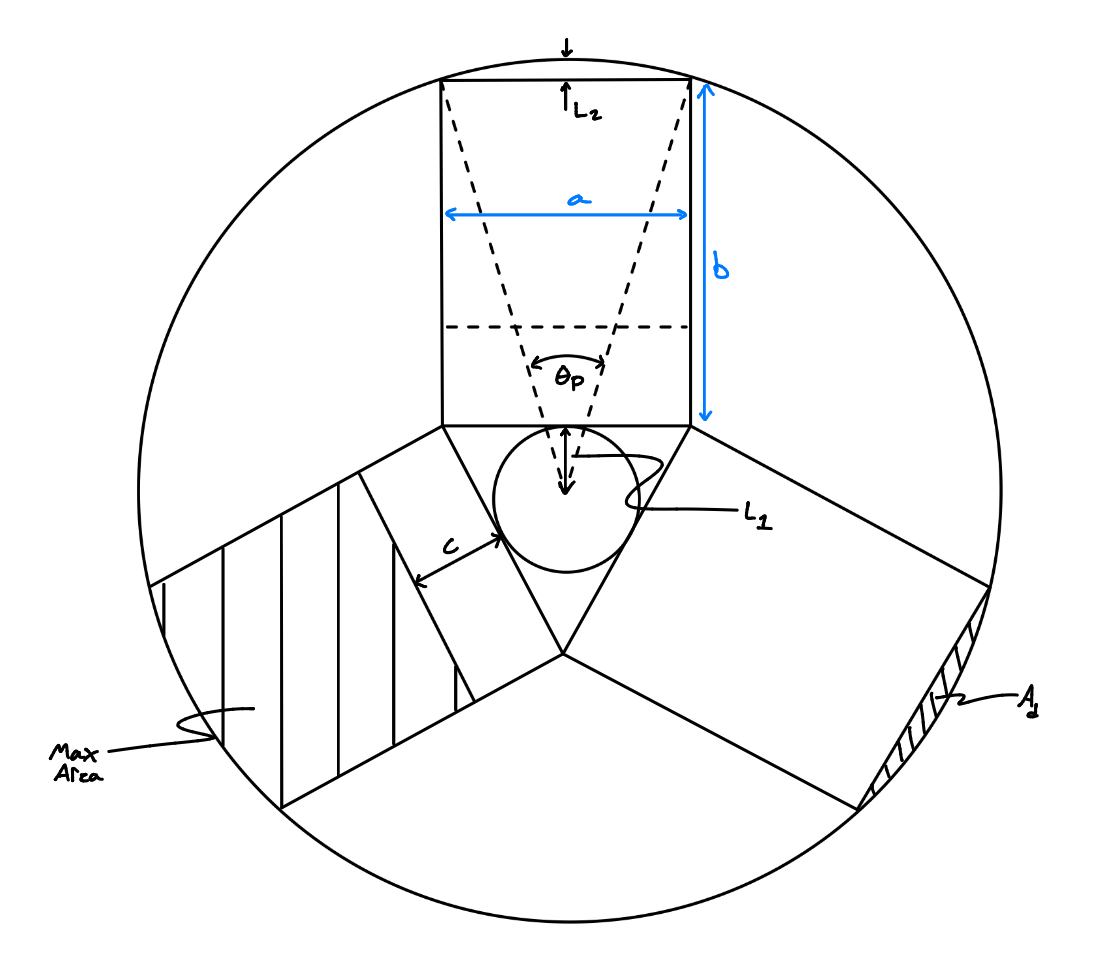

*Figure 2 — Petal geometry (three rectangular petals; the shaded petal is the area being maximized).*

Each petal is a rectangle $a \times b$ whose outer corners touch the body circle, plus the circular segment $A_d$ between its outer edge (a chord) and the body wall. The inner edges of the three petals form an equilateral triangle of side $a$. The inner strip of length $c$ never leaves the body (actuation tolerance), so it is not counted as exposed area.

**(i) Petal width $a$.** The outer edge is a chord subtending $\theta_p$ at the center. Splitting the isosceles triangle (two sides $R$, apex angle $\theta_p$) in half:
$$a = 2R\sin\frac{\theta_p}{2}$$

**(ii) $L_1$, center to inner edge.** This is the inradius of the equilateral triangle of side $a$: half a side, $a/2$, subtends $30^\circ$ at the incenter, so
$$L_1 = \frac{a}{2}\tan 30^\circ = \frac{a}{2\sqrt{3}}$$

**(iii) $L_2$, chord to arc (sagitta).** The perpendicular distance from the center to a chord of length $a$ is $d=\sqrt{R^2-(a/2)^2}$ by Pythagoras, so
$$L_2 = R - \sqrt{R^2 - \frac{a^2}{4}} = R\left(1-\cos\frac{\theta_p}{2}\right)$$

**(iv) Petal length $b$.**
$$b = R - L_1 - L_2 = \sqrt{R^2-\tfrac{a^2}{4}} - \frac{a}{2\sqrt3}$$

**(v) Segment area $A_d$** (circular sector minus the isosceles triangle):
$$A_d = \frac{R^2\theta_p}{2} - \frac{R^2\sin\theta_p}{2} = \frac{R^2}{2}\left(\theta_p - \sin\theta_p\right)$$

**(vi) Exposed petal area.**
$$A_{petal} = ab - ac + A_d = a\,(b-c) + A_d$$

In [6]:
#Petal area as a function of theta (theta in radians)

def petal_area(theta, R=R_val, c=c_tol):
    a   = 2 * R * np.sin(theta/2)              # petal width (chord)
    L1  = a / (2 * np.sqrt(3))                 # center -> inner edge (triangle inradius)
    L2  = R - np.sqrt(R**2 - a**2/4)           # chord -> arc (sagitta)
    b   = R - L1 - L2                          # petal length
    A_d = (R**2 / 2) * (theta - np.sin(theta)) # circular segment
    return a*b - a*c + A_d

a  = 2 * R_val * np.sin(theta_p/2)              # petal width (chord)
L1  = a / (2 * np.sqrt(3))                 # center -> inner edge (triangle inradius)
L2  = R_val - np.sqrt(R_val**2 - a**2/4)           # chord -> arc (sagitta)
b   = R_val - L1 - L2                          # petal length


print("Length outside the rocket: " + str(b + L2 - c_tol) + " in")

Length outside the rocket: 1.5 in


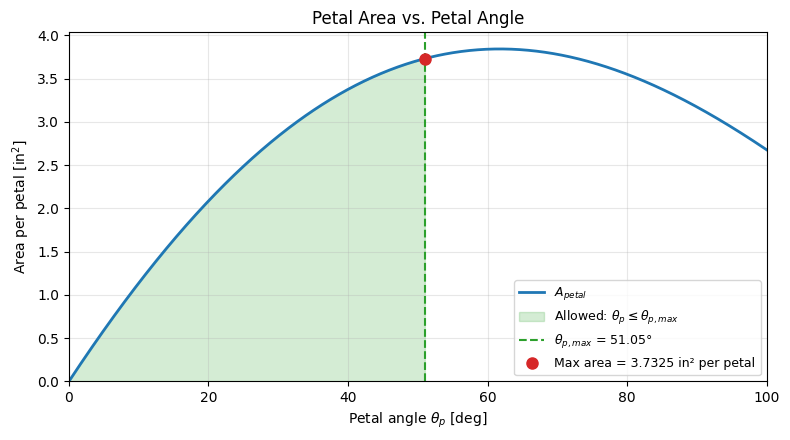

Maximum pedal angle: 51.054 deg
Maximum pedal width: 2.663 in
Max area per petal:  3.7325 in^2
Total area (3):      11.1974 in^2


In [7]:
#Plot area from 0 to 100 deg

theta_deg = np.linspace(0, 100, 1001)
area = petal_area(np.deg2rad(theta_deg))

#Max area in the allowed range (0 to theta_p)
allowed = theta_deg <= np.rad2deg(theta_p)
theta_max_deg = np.rad2deg(theta_p)
A_max = petal_area(theta_p)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(theta_deg, area, color='tab:blue', lw=2, label=f'$A_{{petal}}$')
ax.fill_between(theta_deg[allowed], 0, area[allowed], color='tab:green', alpha=0.2,
                label=r'Allowed: $\theta_p \leq \theta_{p,max}$')
ax.axvline(theta_max_deg, color='tab:green', ls='--', lw=1.5,
           label=fr'$\theta_{{p,max}}$ = {theta_max_deg:.2f}°')
ax.plot(theta_max_deg, A_max, 'o', color='tab:red', ms=8, zorder=5,
        label=f'Max area = {A_max:.4f} in² per petal')


ax.set_xlim(0, 100)
ax.set_ylim(bottom=0)
ax.set_xlabel(r'Petal angle $\theta_p$ [deg]')
ax.set_ylabel(r'Area per petal [in$^2$]')
ax.set_title(f'Petal Area vs. Petal Angle')
ax.grid(alpha=0.3)
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

print(f"Maximum pedal angle: {theta_max_deg:.3f} deg")
print(f"Maximum pedal width: {(2 * R_val * np.sin(theta_p / 2)):.3f} in")
print(f"Max area per petal:  {A_max:.4f} in^2")
print(f"Total area (3):      {3*A_max:.4f} in^2")

In [8]:
# ---- Optimized petal dimensions -> 25_26_MoS_Parameters (SI) -----------------
IN2M = 0.0254

_a  = 2 * R_val * np.sin(theta_p / 2)            # [in] petal width at the optimum
_L1 = _a / (2 * np.sqrt(3))                      # [in]
_L2 = R_val - np.sqrt(R_val**2 - _a**2 / 4)      # [in]
_b  = R_val - _L1 - _L2                          # [in]

PETAL_COUNT      = 3                                   # one between each pair of fins
PETAL_ANGLE      = theta_p                             # rad  constrained optimum
PETAL_WIDTH      = _a * IN2M                           # m    petal width (chord, a)
PETAL_LENGTH     = _b * IN2M                           # m    full petal length (b)
PETAL_H_MAX      = (_b + _L2 - c_tol) * IN2M           # m    exposed length at 100% deployment
PETAL_C_TOL      = c_tol * IN2M                        # m    length kept inside the body
PETAL_AREA       = petal_area(theta_p) * IN2M**2       # m^2  exposed area per petal
PETAL_AREA_TOTAL = PETAL_COUNT * PETAL_AREA            # m^2  all petals, full deployment